In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
df=pd.read_csv('tamil_movies_2015_2026.csv')


In [5]:
df.head()

,Movie_ID,Title,Overview,Overview_WordCount,Genres,Director,Cast,Production_Company,Release_Date,Release_Year,...,Runtime_Minutes,Budget_Local_Currency,Revenue_Local_Currency,Budget_Crores,Revenue_Crores,Profit_Local_Currency,ROI_Percent,Popularity_Score,Vote_Average,Vote_Count
0,1235877,Jana Nayagan,A clash of ideologies. One stands for the peop...,41,"Action, Drama",H. Vinoth,"Vijay, Pooja Hegde, Bobby Deol, Mamitha Baiju,...",KVN Productions,22-07-2026,2026,...,183,0.000000e+00,0.0,0.0,0.00,0.000000e+00,0.00,33.6214,5.500,10
1,1509599,Gatta Kusthi 2,"Picks up after the first film, with Veera and ...",27,"Comedy, Drama",Chella Ayyavu,"Vishnu Vishal, Aishwarya Lekshmi, Zara Zyanna,...",Vels Film International,03-07-2026,2026,...,153,0.000000e+00,0.0,0.0,0.00,0.000000e+00,0.00,27.6505,3.625,4
2,1432631,Idhayam Murali,A young man navigates the complexities of unre...,28,"Romance, Comedy, Drama",Aakash Baskaran,"Atharvaa Murali, Fahadh Faasil, Preity Mukhund...",Dawn Pictures,10-07-2026,2026,...,164,0.000000e+00,0.0,0.0,0.00,0.000000e+00,0.00,21.8000,7.700,3
3,921711,Tamil Rockers,4 Major characters running for the Money facin...,24,"Comedy, Thriller",Barani Jayapal,"Premji Amaran, Meenakshi Dixit, VTV Ganesh, S....",Jaswanth Super Cinemas,31-12-2021,2021,...,98,0.000000e+00,0.0,0.0,0.00,0.000000e+00,0.00,16.4506,4.750,4
4,1367220,Karuppu,"In a world where justice falters, guardian dei...",26,"Action, Fantasy",RJ Balaji,"Suriya, Trisha Krishnan, RJ Balaji, Indrans, A...",Dream Warrior Pictures,14-05-2026,2026,...,152,1.336000e+09,279314096.5,133.6,27.93,-1.056686e+09,-79.09,12.5282,6.700,23


In [6]:
df.shape

(2333, 22)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2333 entries, 0 to 2332
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Movie_ID                2333 non-null   int64  
 1   Title                   2333 non-null   object 
 2   Overview                2240 non-null   object 
 3   Overview_WordCount      2333 non-null   int64  
 4   Genres                  2156 non-null   object 
 5   Director                2333 non-null   object 
 6   Cast                    2241 non-null   object 
 7   Production_Company      2333 non-null   object 
 8   Release_Date            2333 non-null   object 
 9   Release_Year            2333 non-null   int64  
 10  Release_Month           2333 non-null   int64  
 11  Release_DayOfWeek       2333 non-null   object 
 12  Runtime_Minutes         2333 non-null   int64  
 13  Budget_Local_Currency   2333 non-null   float64
 14  Revenue_Local_Currency  2333 non-null   

In [9]:
df.columns

Index(['Movie_ID', 'Title', 'Overview', 'Overview_WordCount', 'Genres',
       'Director', 'Cast', 'Production_Company', 'Release_Date',
       'Release_Year', 'Release_Month', 'Release_DayOfWeek', 'Runtime_Minutes',
       'Budget_Local_Currency', 'Revenue_Local_Currency', 'Budget_Crores',
       'Revenue_Crores', 'Profit_Local_Currency', 'ROI_Percent',
       'Popularity_Score', 'Vote_Average', 'Vote_Count'],
      dtype='object')

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
print("Total Years:", df['Release_Year'].nunique())

print("Total Movies:", df['Title'].nunique())

Total Years: 12
Total Movies: 2318


In [13]:
yearly_movies = df['Release_Year'].value_counts().sort_index()

print(yearly_movies)

Release_Year
2015    151
2016    168
2017    175
2018    181
2019    187
2020    122
2021    171
2022    203
2023    260
2024    253
2025    310
2026    152
Name: count, dtype: int64


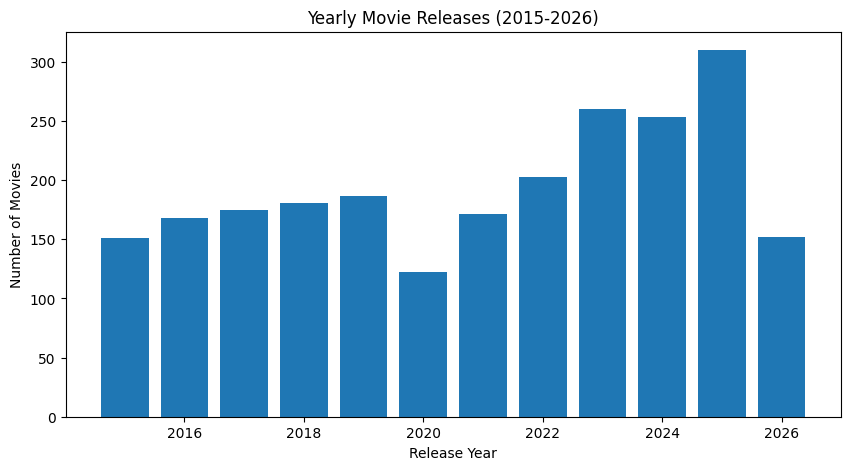

In [15]:
plt.figure(figsize=(10,5))

plt.bar(yearly_movies.index, yearly_movies.values)

plt.title('Yearly Movie Releases (2015-2026)')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')

plt.show()

In [16]:
# Average movie

movies = df[df['Release_Year'].between(2015, 2026)]

top_movies = movies.sort_values(
    by='Vote_Average',
        ascending=False
        ).head(5)

top_movies[['Title', 'Release_Year',
                          'Vote_Average']]

,Title,Release_Year,Vote_Average
2221,Butterfly,2025,10.0
63,Saa Vee,2025,10.0
1330,Kayalin Osai,2024,10.0
1358,Katra Thaliya,2024,10.0
2026,Mohana,2018,10.0


In [18]:
movies_2025 = df[df['Release_Year'] == 2025]

monthly_movies = movies_2025['Release_Month'].value_counts().sort_index()

print(monthly_movies)

Release_Month
1     28
2     24
3     33
4     20
5     29
6     22
7     28
8     26
9     25
10    24
11    33
12    18
Name: count, dtype: int64


In [19]:
# most popular movies by popular score

movies_2015_2026 = df[df['Release_Year'].between(2015, 2026)]

most_popular = movies_2015_2026.sort_values(
    by='Popularity_Score',
    ascending=False
).head(3)

most_popular[['Title', 'Release_Year', 'Popularity_Score']]

,Title,Release_Year,Popularity_Score
0,Jana Nayagan,2026,33.6214
1,Gatta Kusthi 2,2026,27.6505
2,Idhayam Murali,2026,21.8000


In [20]:
# Best movie by vote count & average , popular score

best_movie = df.sort_values(
      by=['Vote_Average', 'Vote_Count', 'Popularity_Score'],
          ascending=False
          ).head(3)

best_movie[['Title', 'Release_Year',
                      'Vote_Average', 'Vote_Count',
                                  'Popularity_Score']]


,Title,Release_Year,Vote_Average,Vote_Count,Popularity_Score
63,Saa Vee,2025,10.0,3,2.5949
875,Friday,2025,10.0,2,1.1214
2003,Seri... Ippo Enna Panlam?,2023,10.0,2,0.4291
